 1 Install TensorFlow Recommenders and Import libraries

In [1]:

import sys
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_recommenders as tfrs

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("TensorFlow Recommenders:", tfrs.__version__)
print("Devices:", tf.config.list_physical_devices())



Python: c:\Users\yatha\Desktop\personalized-recommendation-engine\.venv\Scripts\python.exe
NumPy: 1.26.4
Pandas: 2.2.2
TensorFlow: 2.15.1
TensorFlow Recommenders: v0.7.3
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### 1 Load the processed datasets


Define paths and load data

In [2]:

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "runs" / "models"
REPORT_DIR = PROJECT_ROOT / "runs" / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

retrieval_train_df = pd.read_csv(
    PROCESSED_DIR / "retrieval_train.csv"
)

train_df = pd.read_csv(
    PROCESSED_DIR / "train.csv"
)

validation_df = pd.read_csv(
    PROCESSED_DIR / "validation.csv"
)

test_df = pd.read_csv(
    PROCESSED_DIR / "test.csv"
)

user_mapping = pd.read_csv(
    PROCESSED_DIR / "user_mapping.csv"
)

movie_mapping = pd.read_csv(
    PROCESSED_DIR / "movie_mapping.csv"
)

print("Retrieval Training:", retrieval_train_df.shape)
print("Full Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

print("Users:", len(user_mapping))
print("Movies:", len(movie_mapping))

display(retrieval_train_df.head())


Retrieval Training: (39071, 7)
Full Training: (80419, 6)
Validation: (9818, 6)
Test: (10599, 6)
Users: 610
Movies: 9742


,userId,movieId,rating,timestamp,user_idx,movie_idx,label
0,1,804,4.0,2000-07-30 18:08:19+00:00,0,632,1
1,1,1210,5.0,2000-07-30 18:08:19+00:00,0,911,1
2,1,2018,5.0,2000-07-30 18:08:43+00:00,0,1493,1
3,1,2628,4.0,2000-07-30 18:08:43+00:00,0,1979,1
4,1,2826,4.0,2000-07-30 18:08:43+00:00,0,2126,1


Set model configuration

In [21]:

NUM_USERS = len(user_mapping)
NUM_MOVIES = len(movie_mapping)

EMBEDDING_DIM = 64
BATCH_SIZE = 256
EPOCHS = 5
LEARNING_RATE = 0.001

print("Number of Users:", NUM_USERS)
print("Number of Movies:", NUM_MOVIES)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)


Number of Users: 610
Number of Movies: 9742
Embedding Dimension: 64
Batch Size: 256
Epochs: 5


### 2 Prepare TensorFlow datasets

Create training and validation datasets

In [24]:

positive_validation_df = validation_df[
    validation_df["rating"] >= 4.0
].copy()

train_features = {
    "user_idx": retrieval_train_df["user_idx"].to_numpy(
        dtype=np.int32
    ),
    "movie_idx": retrieval_train_df["movie_idx"].to_numpy(
        dtype=np.int32
    ),
}

validation_features = {
    "user_idx": positive_validation_df["user_idx"].to_numpy(
        dtype=np.int32
    ),
    "movie_idx": positive_validation_df["movie_idx"].to_numpy(
        dtype=np.int32
    ),
}

train_dataset = tf.data.Dataset.from_tensor_slices(
    train_features
)

train_dataset = (
    train_dataset
    .shuffle(
        buffer_size=len(retrieval_train_df),
        seed=42
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    validation_features
)

validation_dataset = (
    validation_dataset
    .batch(BATCH_SIZE)
    .prefetch(1)
)

print("Training examples:", len(retrieval_train_df))
print("Positive validation examples:", len(positive_validation_df))


Training examples: 39071
Positive validation examples: 4451


Verify a batch

In [25]:

for batch in train_dataset.take(1):

    print("User indices:", batch["user_idx"][:10].numpy())

    print("Movie indices:", batch["movie_idx"][:10].numpy())

    print("Batch size:", batch["user_idx"].shape[0])


User indices: [274 209 476  56 267 167 602 232 565 497]
Movie indices: [ 245 6059  905 2350   37 6327 1404 3194  277  506]
Batch size: 256


### 3 Build the User Tower

User Tower

In [26]:

def build_user_tower():

    user_input = tf.keras.Input(
        shape=(),
        dtype=tf.int32,
        name="user_idx"
    )

    user_embedding = tf.keras.layers.Embedding(
        input_dim=NUM_USERS,
        output_dim=EMBEDDING_DIM,
        name="user_embedding"
    )(user_input)

    hidden = tf.keras.layers.Dense(
        128,
        activation="relu",
        name="user_dense"
    )(user_embedding)

    output = tf.keras.layers.Dense(
        EMBEDDING_DIM,
        name="user_output"
    )(hidden)

    return tf.keras.Model(
        inputs=user_input,
        outputs=output,
        name="user_tower"
    )


user_tower = build_user_tower()

user_tower.summary()


Model: "user_tower"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 user_idx (InputLayer)       [(None,)]                 0         
                                                                 
 user_embedding (Embedding)  (None, 64)                39040     
                                                                 
 user_dense (Dense)          (None, 128)               8320      
                                                                 
 user_output (Dense)         (None, 64)                8256      
                                                                 
Total params: 55616 (217.25 KB)
Trainable params: 55616 (217.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### 4 Build the Movie Tower

Movie Tower

In [27]:

def build_movie_tower():

    movie_input = tf.keras.Input(
        shape=(),
        dtype=tf.int32,
        name="movie_idx"
    )

    movie_embedding = tf.keras.layers.Embedding(
        input_dim=NUM_MOVIES,
        output_dim=EMBEDDING_DIM,
        name="movie_embedding"
    )(movie_input)

    hidden = tf.keras.layers.Dense(
        128,
        activation="relu",
        name="movie_dense"
    )(movie_embedding)

    output = tf.keras.layers.Dense(
        EMBEDDING_DIM,
        name="movie_output"
    )(hidden)

    return tf.keras.Model(
        inputs=movie_input,
        outputs=output,
        name="movie_tower"
    )


movie_tower = build_movie_tower()

movie_tower.summary()


Model: "movie_tower"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 movie_idx (InputLayer)      [(None,)]                 0         
                                                                 
 movie_embedding (Embedding  (None, 64)                623488    
 )                                                               
                                                                 
 movie_dense (Dense)         (None, 128)               8320      
                                                                 
 movie_output (Dense)        (None, 64)                8256      
                                                                 
Total params: 640064 (2.44 MB)
Trainable params: 640064 (2.44 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


### 5 Create the Two-Tower Retrieval Model

Define the model class

In [28]:

class TwoTowerRetrievalModel(tfrs.Model):

    def __init__(self, user_tower, movie_tower):

        super().__init__()

        self.user_tower = user_tower
        self.movie_tower = movie_tower

        self.retrieval_task = tfrs.tasks.Retrieval()

    def compute_loss(self, features, training=False):

        user_embeddings = self.user_tower(
            features["user_idx"],
            training=training
        )

        movie_embeddings = self.movie_tower(
            features["movie_idx"],
            training=training
        )

        loss = self.retrieval_task(
            user_embeddings,
            movie_embeddings
        )

        return loss


two_tower_model = TwoTowerRetrievalModel(
    user_tower=user_tower,
    movie_tower=movie_tower
)

two_tower_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )
)

print("Two-Tower Retrieval Model created successfully!")


Two-Tower Retrieval Model created successfully!


#### 6 Train the model

In [29]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history = two_tower_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("Training completed successfully!")


Epoch 1/5


153/153 [==============================] - 4s 19ms/step - loss: 1408.7846 - regularization_loss: 0.0000e+00 - total_loss: 1408.7846 - val_loss: 454.5437 - val_regularization_loss: 0.0000e+00 - val_total_loss: 454.5437
Epoch 2/5
153/153 [==============================] - 3s 17ms/step - loss: 1345.2809 - regularization_loss: 0.0000e+00 - total_loss: 1345.2809 - val_loss: 447.8986 - val_regularization_loss: 0.0000e+00 - val_total_loss: 447.8986
Epoch 3/5
153/153 [==============================] - 3s 16ms/step - loss: 1280.9819 - regularization_loss: 0.0000e+00 - total_loss: 1280.9819 - val_loss: 444.5480 - val_regularization_loss: 0.0000e+00 - val_total_loss: 444.5480
Epoch 4/5
153/153 [==============================] - 2s 16ms/step - loss: 1239.6367 - regularization_loss: 0.0000e+00 - total_loss: 1239.6367 - val_loss: 458.3861 - val_regularization_loss: 0.0000e+00 - val_total_loss: 458.3861
Epoch 5/5
153/153 [==============================] - 2s 15ms/step - loss: 1210.5827 - regularizati

### 7 Visualize the training results

Plot training and validation loss

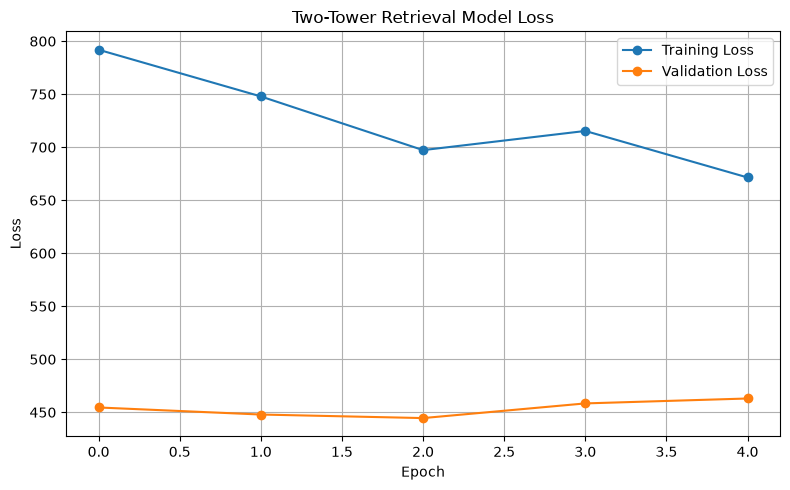

In [31]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Two-Tower Retrieval Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### 8 Generate User and Movie Embeddings

Generate movie embeddings

In [32]:

all_movie_indices = tf.constant(
    np.arange(NUM_MOVIES, dtype=np.int32)
)

movie_embeddings = movie_tower(
    all_movie_indices,
    training=False
).numpy()

print("Movie Embeddings Shape:", movie_embeddings.shape)

assert movie_embeddings.shape == (
    NUM_MOVIES,
    EMBEDDING_DIM
)


Movie Embeddings Shape: (9742, 64)


Generate user embeddings

In [33]:

all_user_indices = tf.constant(
    np.arange(NUM_USERS, dtype=np.int32)
)

user_embeddings = user_tower(
    all_user_indices,
    training=False
).numpy()

print("User Embeddings Shape:", user_embeddings.shape)

assert user_embeddings.shape == (
    NUM_USERS,
    EMBEDDING_DIM
)


User Embeddings Shape: (610, 64)


### 9 Save the models


Save model files and embeddings

In [34]:

user_tower.save(
    MODEL_DIR / "user_tower.keras"
)

movie_tower.save(
    MODEL_DIR / "movie_tower.keras"
)

np.save(
    MODEL_DIR / "user_embeddings.npy",
    user_embeddings
)

np.save(
    MODEL_DIR / "movie_embeddings.npy",
    movie_embeddings
)

print("User Tower saved.")
print("Movie Tower saved.")
print("User embeddings saved.")
print("Movie embeddings saved.")


User Tower saved.
Movie Tower saved.
User embeddings saved.
Movie embeddings saved.


Verify saved files

In [35]:

for file in sorted(MODEL_DIR.iterdir()):

    print(
        file.name,
        "-",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )


movie_embeddings.npy - 2435.62 KB
movie_tower.keras - 2514.14 KB
user_embeddings.npy - 152.62 KB
user_tower.keras - 231.12 KB
